<a href="https://colab.research.google.com/github/FOFM030711/SIMULACION-II/blob/main/Actividad4_Black_Scholes_SymPy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <span style="color:olive;">**Actividad 4 — Ecuación de Black-Scholes. Solución analítica**</span>

<span style="color:teal;">**Nombres:** </span>
* Florencio Florencio Miriam Lizhet
* Jerónimo López Annette Michelle

<span style="color:magenta;">**Objetivo**</span>

Resolver **analíticamente** la ecuación de Black-Scholes reduciéndola a la ecuación del calor, y usar SymPy para verificar cada paso y calcular el precio de una opción call europea de IBM. **Con el uso de la librería  SymPy, incluidas las gráficas** (`sympy.plotting`), con los datos del ejercicio sustituidos desde el planteamiento.


## <span style="color:purple;">**Estructura de la actividad 4:**</span>
| Contenido |
|---|
| Planteamiento: la EDP (1) y la condición terminal |
| Cambio de tiempo $\tau = T-t$ |
| Cambio logarítmico $S=e^x$ |
| Transformación exponencial $u=e^{\alpha x+\beta\tau}Z$ → ecuación del calor |
| Fórmula de Green (núcleo del calor) y regreso a $V$ |
| Integral para el payoff del call → fórmula de Black-Scholes |
| Ejercicio: opción call de IBM |
| Gráficas en 3D: superficie $V(S,\tau)$ y solución $u(x,\tau)$ de la ecuación del calor |


In [ ]:
# Importamos SymPy y definimos el formato de impresión matemático
import sympy as sp
from sympy.plotting import plot, plot3d, plot_parametric   # gráficas 2D, 3D y curvas paramétricas de SymPy
sp.init_printing(use_latex='mathjax')                      # las expresiones se muestran en LaTeX

## <span style="color:purple;">**Planteamiento**</span>

$V(S,t)$ es el precio de la opción en el instante $t\in[0,T]$ con precio de la acción $S>0$. Parámetros: $\sigma>0$ volatilidad, $r>0$ tasa libre de riesgo, $q\ge 0$ tasa de dividendos, $T$ vencimiento y $E$ precio de ejercicio (strike).

**EDP de Black-Scholes (1):**
$$\frac{\partial V}{\partial t}+\frac12\sigma^2S^2\frac{\partial^2V}{\partial S^2}+(r-q)S\frac{\partial V}{\partial S}-rV=0 .$$

**Condición terminal** (payoff de un call): $\overline V(S)=V(S,T)=(S-E)^+=\max(S-E,0)$.

En SymPy declaramos los símbolos con `positive=True`; eso ayuda a que `simplify` e `integrate` tomen decisiones correctas (por ejemplo, $\sqrt{\sigma^2}=\sigma$).

In [ ]:
# Símbolos del modelo (todos positivos; q puede ser 0, pero lo dejamos positivo para simplificar)
S, t, T, tau = sp.symbols('S t T tau', positive=True)
sigma, r, q, E = sp.symbols('sigma r q E', positive=True)

In [ ]:
# V(S,t): función incógnita de la ecuación (1)
V = sp.Function('V')

In [ ]:
# Ecuación de Black-Scholes (1): el lado izquierdo igualado a 0
BS = (sp.diff(V(S, t), t)
      + sp.Rational(1, 2)*sigma**2*S**2*sp.diff(V(S, t), S, 2)
      + (r - q)*S*sp.diff(V(S, t), S)
      - r*V(S, t))
sp.Eq(BS, 0)

       2                                                                 
 2  2 ∂                                                                  
S ⋅σ ⋅───(V(S, t))                                                       
        2                                                                
      ∂S                        ∂                         ∂              
────────────────── + S⋅(-q + r)⋅──(V(S, t)) - r⋅V(S, t) + ──(V(S, t)) = 0
        2                       ∂S                        ∂t             

### <span style="color:purple;">**Datos del problema**</span>

El ejercicio (Paso 5) fija los parámetros de la opción call sobre **IBM**:

| Dato | Símbolo | Valor |
|---|---|---|
| Precio al contado | $S_0$ | 58.5 |
| Volatilidad | $\sigma$ | 0.29 |
| Tasa libre de riesgo | $r$ | 0.04 |
| Dividendos (IBM no paga) | $q$ | 0 |
| Precio de ejercicio | $E$ | 60 |
| Vencimiento | $T$ | 0.3 años |

Los guardamos en dos diccionarios con `Rational` (fracciones exactas, para evitar errores de redondeo):
* `param`: solo los **parámetros** ($\sigma,r,q,E,T$). Se sustituyen en las ecuaciones y quedan libres $S$, $t$, $\tau$, $x$.
* `datos`: `param` más el punto de evaluación $S=58.5$, $t=0$.

A partir de aquí, **cada paso se muestra primero en forma simbólica y después con los números ya sustituidos**.

In [ ]:
# Parámetros del ejercicio de IBM (fracciones exactas)
param = {sigma: sp.Rational(29, 100),   # volatilidad 29 %
         r:     sp.Rational(4, 100),    # tasa libre de riesgo 4 %
         q:     0,                      # IBM no paga dividendos
         E:     60,                     # precio de ejercicio (strike)
         T:     sp.Rational(3, 10)}     # vencimiento 0.3 años

# Parámetros + punto donde se pide el precio: V(58.5, 0)
datos = {**param, S: sp.Rational(585, 10), t: 0}

# Ecuación (1) con los números sustituidos (quedan libres S y t)
BS_num = BS.subs(param)
sp.Eq(BS_num, 0)

        2                                                      
     2 ∂                                                       
841⋅S ⋅───(V(S, t))     ∂                                      
         2            S⋅──(V(S, t))                            
       ∂S               ∂S            V(S, t)   ∂              
─────────────────── + ───────────── - ─────── + ──(V(S, t)) = 0
       20000               25           25      ∂t             

In [ ]:
# Condición terminal (= condición inicial tras el cambio de tiempo): Vbar(S) = (S - E)^+
# Se escribe con Piecewise para que SymPy pueda graficarla sin problemas
Vbar_S   = sp.Piecewise((S - E, S > E), (0, True))
Vbar_num = Vbar_S.subs(param)                      # con E = 60
display(sp.Eq(sp.Function('Vbar')(S), Vbar_num))
print("Payoff en S = 58.5 :", Vbar_num.subs(S, datos[S]), " (fuera del dinero: 58.5 < 60)")

       ⎧S - 60  for S > 60
V̅(S) = ⎨                  
       ⎩  0     otherwise 

Payoff en S = 58.5 : 0  (fuera del dinero: 58.5 < 60)


### <span style="color:purple;">**Gráfica de la condición inicial**</span>

Graficamos con SymPy el payoff $\overline V(S)=(S-60)^+$. La recta gris marca el strike $E=60$ y la roja el precio actual de IBM, $S_0=58.5$. Esta es la condición terminal de (1), que se vuelve condición **inicial** ($\tau=0$) de la ecuación parabólica después del Paso 1.

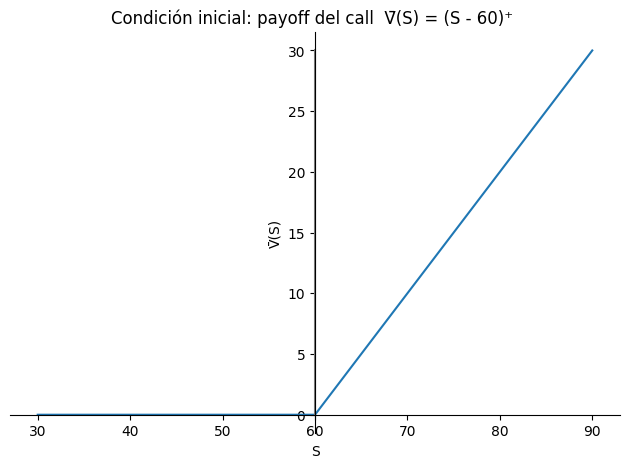

In [ ]:
# Recta vertical con SymPy: curva paramétrica (x0, tt) para tt entre 0 y ymax
def linea_vertical(x0, ymax, color):
    tt = sp.symbols('tt')
    # el término 1e-9*tt evita que la coordenada x sea constante (SymPy la vectoriza sin problemas)
    return plot_parametric(x0 + sp.Float('1e-9')*tt, tt, (tt, 0, ymax),
                           show=False, line_color=color)

p0 = plot(Vbar_num, (S, 30, 90), show=False, line_color='tab:blue',
          title='Condición inicial: payoff del call  V̄(S) = (S - 60)⁺ ',
          xlabel='S', ylabel='V̄(S)')
p0.extend(linea_vertical(60, 30, 'gray'))                       # strike E = 60
p0.show()

## <span style="color:blue;">**Paso 1 — Transformación del tiempo: $\tau=T-t$**</span>

La EDP (1) se resuelve "hacia atrás" desde $t=T$. Para que el tiempo fluya hacia adelante hacemos $\tau=T-t$, de modo que $t=T\Rightarrow\tau=0$ y $t=0\Rightarrow\tau=T$. Definimos
$$W(S,\tau)=V(S,T-\tau).$$
Por la regla de la cadena $\dfrac{\partial V}{\partial t}=-\dfrac{\partial W}{\partial\tau}$ (el signo cambia porque $d\tau=-dt$). Las derivadas respecto a $S$ no cambian.

Resultado:
$$\frac{\partial W}{\partial\tau}=\frac12\sigma^2S^2\frac{\partial^2W}{\partial S^2}+(r-q)S\frac{\partial W}{\partial S}-rW,\qquad W(S,0)=\overline V(S).$$

In [ ]:
# W(S, tau) = V(S, T - tau). Reescribimos (1) sustituyendo V por W y dV/dt por -dW/dtau
W = sp.Function('W')

In [ ]:
# Regla de la cadena: dV/dt = -dW/dtau  -> se sustituye directamente en la ecuación
BS_tau = (-sp.diff(W(S, tau), tau)
          + sp.Rational(1, 2)*sigma**2*S**2*sp.diff(W(S, tau), S, 2)
          + (r - q)*S*sp.diff(W(S, tau), S)
          - r*W(S, tau))

In [ ]:
# Despejamos W_tau para ver la forma "parabólica" W_tau = ...
W_tau = sp.solve(sp.Eq(BS_tau, 0), sp.diff(W(S, tau), tau))[0]
sp.Eq(sp.diff(W(S, tau), tau), W_tau)

                     2                                                          
               2  2 ∂                                                           
              S ⋅σ ⋅───(W(S, τ))                                                
                      2                                                         
∂                   ∂S                 ∂                 ∂                      
──(W(S, τ)) = ────────────────── - S⋅q⋅──(W(S, τ)) + S⋅r⋅──(W(S, τ)) - r⋅W(S, τ)
∂τ                    2                ∂S                ∂S                     

In [ ]:
# Misma ecuación del paso 1 con los parámetros de IBM sustituidos
sp.Eq(sp.diff(W(S, tau), tau), W_tau.subs(param))

                      2                                    
                   2 ∂                                     
              841⋅S ⋅───(W(S, τ))     ∂                    
                       2            S⋅──(W(S, τ))          
∂                    ∂S               ∂S            W(S, τ)
──(W(S, τ)) = ─────────────────── + ───────────── - ───────
∂τ                   20000               25           25   

## <span style="color:blue;">**Paso 2 — Transformación logarítmica: $S=e^x,\; x=\ln S$**</span>

Los coeficientes $S^2$ y $S$ de la EDP hacen que no tenga coeficientes constantes.

 Con $S=e^x$ (válido porque $S\in(0,\infty)\iff x\in(-\infty,\infty)$) definimos
$$Z(x,\tau)=W(e^x,\tau),\qquad\text{es decir}\quad W(S,\tau)=Z(\ln S,\tau).$$
Regla de la cadena con $x=\ln S$:
$$S\,W_S=Z_x,\qquad S^2W_{SS}=Z_{xx}-Z_x .$$
(Se obtiene porque $W_S=Z_x/S$ y $W_{SS}=(Z_{xx}-Z_x)/S^2$.)

Sustituyendo:
$$Z_\tau=\frac12\sigma^2Z_{xx}+\Big(r-q-\frac{\sigma^2}{2}\Big)Z_x-rZ,\qquad Z(x,0)=\overline V(e^x),\;\; x\in(-\infty,\infty).$$
Ya tiene **coeficientes constantes**.

Verificanmis con SymPy que las reglas de la cadena son correctas.

In [ ]:
x = sp.symbols('x', real=True)
Zf = sp.Function('Z')

# Verificación de las reglas de la cadena con una función de prueba arbitraria.
# W(S,tau) = Z(ln S, tau). Derivamos con SymPy directamente:
Wtest = Zf(sp.log(S), tau)
W_S  = sp.diff(Wtest, S)
W_SS = sp.diff(Wtest, S, 2)

In [ ]:
# Sustituimos ln S = x en las expresiones S*W_S y S^2*W_SS usando una función concreta
# (comprobamos con Z(x,tau)= exp(3x)*tau + x**2 para que el resultado sea explícito)
Zprueba = lambda xx, tt: sp.exp(3*xx)*tt + xx**2
Wp = Zprueba(sp.log(S), tau)

lhs1 = sp.simplify(S*sp.diff(Wp, S))                      # S*W_S
rhs1 = sp.diff(Zprueba(x, tau), x).subs(x, sp.log(S))     # Z_x
lhs2 = sp.simplify(S**2*sp.diff(Wp, S, 2))                # S^2*W_SS
rhs2 = (sp.diff(Zprueba(x, tau), x, 2) - sp.diff(Zprueba(x, tau), x)).subs(x, sp.log(S))  # Z_xx - Z_x

In [ ]:
# Ecuación resultante del paso 2: Z_tau = (1/2) sigma^2 Z_xx + (r - q - sigma^2/2) Z_x - r Z
Z = sp.Function('Z')
mu = r - q - sigma**2/2            # coeficiente de Z_x (lo usaremos en el paso 3)

Z_eq = sp.Eq(sp.diff(Z(x, tau), tau),
             sp.Rational(1, 2)*sigma**2*sp.diff(Z(x, tau), x, 2)
             + mu*sp.diff(Z(x, tau), x) - r*Z(x, tau))
Z_eq

                               2                                      
                            2 ∂                                       
                           σ ⋅───(Z(x, τ))                            
                                2            ⎛          2⎞            
∂                             ∂x             ⎜         σ ⎟ ∂          
──(Z(x, τ)) = -r⋅Z(x, τ) + ─────────────── + ⎜-q + r - ──⎟⋅──(Z(x, τ))
∂τ                                2          ⎝         2 ⎠ ∂x         

In [ ]:
# Ecuación del paso 2 con los parámetros de IBM sustituidos
mu_num = sp.simplify(mu.subs(param))
print("mu = r - q - sigma^2/2 =", mu_num, "≈", sp.N(mu_num, 8))
Z_eq.subs(param)

mu = r - q - sigma^2/2 = -41/20000 ≈ -0.0020500000


                                                2          
                                               ∂           
                             ∂             841⋅───(Z(x, τ))
                          41⋅──(Z(x, τ))         2         
∂               Z(x, τ)      ∂x                ∂x          
──(Z(x, τ)) = - ─────── - ────────────── + ────────────────
∂τ                25          20000             20000      

          ⎧ x                      
          ⎪ℯ  - 60  for x > log(60)
Z(x, 0) = ⎨                        
          ⎪   0        otherwise   
          ⎩                        

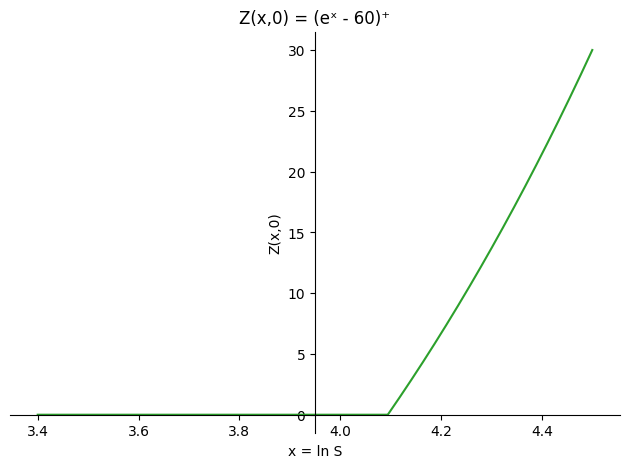

In [ ]:
# Condición inicial tras S = e^x:  Z(x, 0) = Vbar(e^x) = (e^x - E)^+
# (e^x > E  equivale a  x > ln E)
Z0_x = sp.Piecewise((sp.exp(x) - E, x > sp.log(E)), (0, True)).subs(param)
display(sp.Eq(Z(x, 0), Z0_x))

p2 = plot(Z0_x, (x, 3.4, 4.5), show=False, line_color='tab:green',
          title='Z(x,0) = (eˣ - 60)⁺', xlabel='x = ln S', ylabel='Z(x,0)')
p2.show()

## <span style="color:blue;">**Paso 3 — Transformación exponencial → ecuación del calor**</span>

Los términos de orden inferior $Z$ y $Z_x$ se eliminan con
$$u(x,\tau)=e^{\alpha x+\beta\tau}Z(x,\tau)\quad\Longleftrightarrow\quad Z(x,\tau)=e^{-\alpha x-\beta\tau}u(x,\tau),$$
eligiendo $\alpha,\beta$ para que la ecuación quede como la del calor (2):
$$u_\tau=a^2u_{xx},\qquad a^2=\frac{\sigma^2}{2}.$$



In [ ]:
alpha, beta = sp.symbols('alpha beta', real=True)
u = sp.Function('u')

In [ ]:
# Z = e^{-alpha x - beta tau} u(x, tau)
Zsub = sp.exp(-alpha*x - beta*tau)*u(x, tau)

In [ ]:
# Ecuación del paso 2 con Z sustituida:  (Z_tau - [lado derecho]) = 0
resid = (sp.diff(Zsub, tau)
         - (sp.Rational(1, 2)*sigma**2*sp.diff(Zsub, x, 2)
            + mu*sp.diff(Zsub, x) - r*Zsub))

In [ ]:
# Dividimos entre el factor exponencial y expandimos
resid = sp.expand(sp.simplify(resid/sp.exp(-alpha*x - beta*tau)))
resid

                                                                               ↪
                                                                               ↪
                                                                               ↪
   2  2                                          2                             ↪
  α ⋅σ ⋅u(x, τ)                               α⋅σ ⋅u(x, τ)      2 ∂            ↪
- ───────────── - α⋅q⋅u(x, τ) + α⋅r⋅u(x, τ) - ──────────── + α⋅σ ⋅──(u(x, τ))  ↪
        2                                          2              ∂x           ↪

↪                                                                              ↪
↪                                                                              ↪
↪                                                            2 ∂             σ ↪
↪                                                           σ ⋅──(u(x, τ))     ↪
↪                 ∂                           ∂                ∂x              ↪
↪ - β⋅u(x, τ) + q⋅──(u(x, τ

In [ ]:
# Extraemos los coeficientes de u_x y de u (u_tau y u_xx quedan fijos)
ux  = sp.diff(u(x, tau), x)
coef_ux = resid.coeff(ux)
coef_ux                    # coeficiente de u_x

                2
   2           σ 
α⋅σ  + q - r + ──
               2 

In [ ]:
coef_u  = resid.coeff(u(x, tau))                # coeficiente de u (sin derivadas)
coef_u

   2  2                  2        
  α ⋅σ                α⋅σ         
- ───── - α⋅q + α⋅r - ──── - β + r
    2                  2          

In [ ]:
# Exigimos que ambos sean cero y resolvemos para alpha, beta
sol = sp.solve([coef_ux, coef_u], [alpha, beta], dict=True)[0]
alpha_val = sp.simplify(sol[alpha])
beta_val  = sp.simplify(sol[beta])
display(sp.Eq(alpha, alpha_val))
display(sp.Eq(beta,  beta_val))

              2
             σ 
    -q + r - ──
             2 
α = ───────────
         2     
        σ      

     2            2    2      2    4
    q          q⋅σ    r    r⋅σ    σ 
    ── - q⋅r + ──── + ── + ──── + ──
    2           2     2     2     8 
β = ────────────────────────────────
                    2               
                   σ                

In [ ]:
# Comparamos con las fórmulas teóricas:
#   alpha = (r - q - sigma^2/2)/sigma^2 ,   beta = r + (r - q - sigma^2/2)^2 / (2 sigma^2)
alpha_teo = mu/sigma**2
beta_teo  = r + mu**2/(2*sigma**2)

# Comprobamos que con esos valores queda la ecuación del calor  u_tau = (sigma^2/2) u_xx
resid_final = sp.simplify(resid.subs({alpha: alpha_val, beta: beta_val}))
resid_final   # debe ser:  u_tau - (sigma^2/2) u_xx

      2                        
   2 ∂                         
  σ ⋅───(u(x, τ))              
       2                       
     ∂x             ∂          
- ─────────────── + ──(u(x, τ))
         2          ∂τ         

La expresión final es $$u_\tau-\frac{\sigma^2}{2}u_{xx}$$
Igualando a cero, es decir, la **ecuación del calor** con
$$a^2=\frac{\sigma^2}{2}$$

**Condición inicial:** $u(x,0)=e^{\alpha x}Z(x,0)=e^{\alpha x}\,\overline V(e^x)$.

### <span style="color:blue;">**Paso 3 con los datos de IBM**</span>

Sustituyendo $\sigma=0.29,\ r=0.04,\ q=0$ obtenemos las constantes numéricas de la transformación y el coeficiente de difusión de la ecuación del calor.

In [ ]:
# Constantes numéricas de la transformación u = e^{alpha x + beta tau} Z
alpha_num = sp.simplify(alpha_teo.subs(param))
beta_num  = sp.simplify(beta_teo.subs(param))
a2_num    = sp.simplify((sigma**2/2).subs(param))     # a^2 = sigma^2/2

print("alpha =", alpha_num, "≈", sp.N(alpha_num, 8))
print("beta  =", beta_num,  "≈", sp.N(beta_num, 8))
print("a^2   =", a2_num,    "=", sp.N(a2_num, 8))

alpha = -41/1682 ≈ -0.024375743
beta  = 2692881/67280000 ≈ 0.040024985
a^2   = 841/20000 = 0.042050000


## <span style="color:purple;">**Condición inicial**</span>

La condición inicial de la ecuación del calor sale de la condición terminal de la opción, pasando por las mismas transformaciones:

| Variable | Condición inicial ($\tau=0$) | Con datos de IBM |
|---|---|---|
| $V$ (original, $t=T$) | $\overline V(S)=(S-E)^+$ | $(S-60)^+$ |
| $Z$ (tras $S=e^x$) | $Z(x,0)=\overline V(e^x)=(e^x-E)^+$ | $(e^x-60)^+$ |
| $u$ (ecuación del calor) | $u(x,0)=e^{\alpha x}\,(e^x-E)^+$ | $e^{-0.02438\,x}(e^x-60)^+$ |

Los tres comparten el mismo "quiebre" en $S=E=60$, es decir $x=\ln 60\approx4.094$. La marca roja es el precio actual de IBM, $S_0=58.5$ ($x_0=\ln58.5\approx4.069$), que queda **justo antes del quiebre**.

In [ ]:
# Las tres condiciones iniciales con los datos de IBM, todas en SymPy
Z0_x = sp.Piecewise((sp.exp(x) - E, x > sp.log(E)), (0, True)).subs(param)    # Z(x,0)
u0_x = sp.piecewise_fold(sp.exp(alpha_num*x)*Z0_x)                             # u(x,0) = e^{alpha x} Z(x,0)

display(sp.Eq(sp.Function('Vbar')(S), Vbar_num))
display(sp.Eq(Z(x, 0), Z0_x))
display(sp.Eq(u(x, 0), u0_x))

       ⎧S - 60  for S > 60
V̅(S) = ⎨                  
       ⎩  0     otherwise 

          ⎧ x                      
          ⎪ℯ  - 60  for x > log(60)
Z(x, 0) = ⎨                        
          ⎪   0        otherwise   
          ⎩                        

          ⎧           -41⋅x                  
          ⎪           ──────                 
          ⎪⎛ x     ⎞   1682                  
u(x, 0) = ⎨⎝ℯ  - 60⎠⋅ℯ        for x > log(60)
          ⎪                                  
          ⎪        0             otherwise   
          ⎩                                  

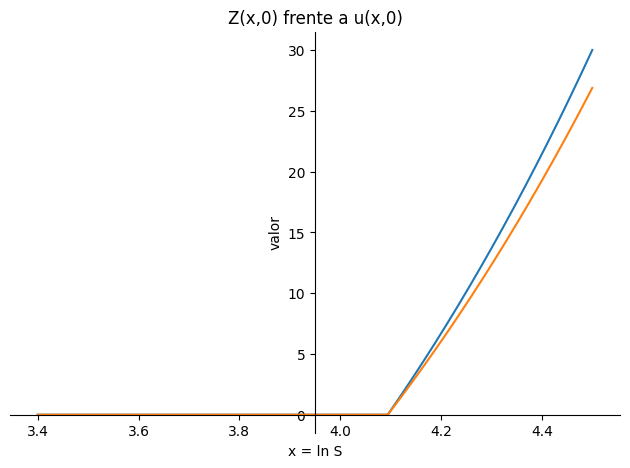

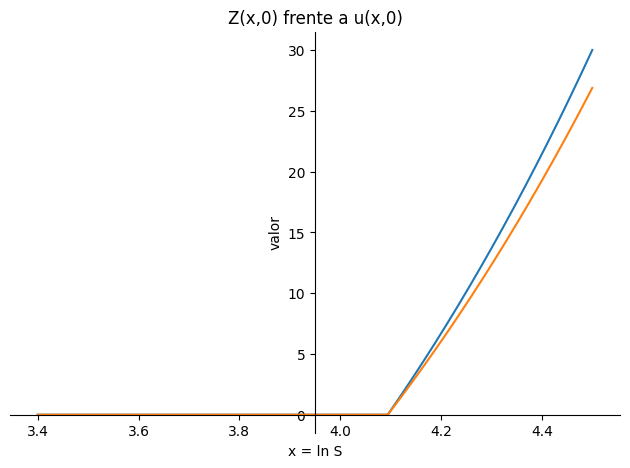

In [ ]:
# (b) Z(x,0) y u(x,0) superpuestas: difieren por el factor e^{alpha x} (alpha ≈ -0.024)
pc = plot(Z0_x, u0_x, (x, 3.4, 4.5),title='Z(x,0) frente a u(x,0)', xlabel='x = ln S', ylabel='valor')
pc.show()

## <span style="color:purple;">**Paso 4 — Fórmula de Green y vuelta hacia atrás $u\to Z\to W\to V$**</span>

Para $u_\tau=a^2u_{xx}$ en $\mathbb R$, la solución con dato inicial $u(s,0)$ es la convolución con el núcleo de Green (núcleo del calor):
$$u(x,\tau)=\frac{1}{\sqrt{4\pi a^2\tau}}\int_{-\infty}^{\infty}e^{-\frac{(x-s)^2}{4a^2\tau}}\,u(s,0)\,ds .$$
Con $a^2=\sigma^2/2$: $4a^2\tau=2\sigma^2\tau$, y queda como en la hoja:
$$u(x,\tau)=\frac{1}{\sqrt{2\sigma^2\pi\tau}}\int_{-\infty}^{\infty}e^{-\frac{(x-s)^2}{2\sigma^2\tau}}u(s,0)\,ds .$$

Primero verificamos con SymPy que el núcleo **sí resuelve** la ecuación del calor.

In [ ]:
# Núcleo del calor  G(x, tau) = 1/sqrt(2 pi sigma^2 tau) * exp(-x^2/(2 sigma^2 tau))
G = sp.exp(-x**2/(2*sigma**2*tau))/sp.sqrt(2*sp.pi*sigma**2*tau)

In [ ]:
# Verificamos G_tau - (sigma^2/2) G_xx = 0
check = sp.simplify(sp.diff(G, tau) - sigma**2/2*sp.diff(G, x, 2))
print("G resuelve la ecuación del calor:", check == 0)

G resuelve la ecuación del calor: True


**Regreso a $V$.** Deshaciendo las transformaciones:

* $u\to Z$: $Z(x,\tau)=e^{-\alpha x-\beta\tau}u(x,\tau)$
* $Z\to W$: $W(S,\tau)=Z(\ln S,\tau)$
* $W\to V$: $V(S,T-\tau)=W(S,\tau)$

con lo cual
$$V(S,T-\tau)=e^{-\beta\tau}e^{-\alpha\ln S}\,u(\ln S,\tau)=\frac{e^{-\beta\tau}}{\sqrt{2\sigma^2\pi\tau}}\,S^{-\alpha}\int_{-\infty}^{\infty}e^{-\frac{(\ln S-s)^2}{2\sigma^2\tau}}e^{\alpha s}\,\overline V(e^s)\,ds .\tag{3}$$

Lo definimos en SymPy como una integral sin evaluar.

In [ ]:
# Ecuación (3) para un payoff genérico Vbar. Se deja como Integral sin evaluar.
s = sp.symbols('s', real=True)
Vbar = sp.Function('Vbar')

xS = sp.log(S)    # x = ln S
integrando = sp.exp(-(xS - s)**2/(2*sigma**2*tau))*sp.exp(alpha*s)*Vbar(sp.exp(s))

V_green = (sp.exp(-beta*tau)/sp.sqrt(2*sp.pi*sigma**2*tau)
           * S**(-alpha)*sp.Integral(integrando, (s, -sp.oo, sp.oo)))
sp.Eq(sp.Symbol('V(S,T-tau)'), V_green)

                          ∞                                 
                          ⌠                                 
                          ⎮                            2    
                          ⎮              -(-s + log(S))     
                          ⎮              ────────────────   
                          ⎮                      2          
                 -α  -β⋅τ ⎮   ⎛ s⎞  α⋅s       2⋅σ ⋅τ        
             √2⋅S  ⋅ℯ    ⋅⎮  V̅⎝ℯ ⎠⋅ℯ   ⋅ℯ                 ds
                          ⌡                                 
                          -∞                                
V(S,T-tau) = ───────────────────────────────────────────────
                                2⋅√π⋅σ⋅√τ                   

## <span style="color:purple;">**Paso 4b — Aplicar el payoff del call: $\overline V(e^s)=(e^s-E)^+$**</span>

El payoff es positivo solo si $e^s>E\iff s>\ln E$. Por tanto la integral se reduce a $s\in(\ln E,\infty)$ con $\overline V(e^s)=e^s-E$:
$$V=\frac{e^{-\beta\tau}S^{-\alpha}}{\sqrt{2\pi\sigma^2\tau}}\int_{\ln E}^{\infty}e^{-\frac{(x-s)^2}{2\sigma^2\tau}}e^{\alpha s}\,(e^s-E)\,ds,\qquad x=\ln S.$$

**Truco: completar el cuadrado.** Con $v=\sigma^2\tau$ y $m=x+\alpha v$:
$$-\frac{(x-s)^2}{2v}+\alpha s=-\frac{(s-m)^2}{2v}+\alpha x+\frac{\alpha^2v}{2}.$$
Lo verificamos con SymPy.

In [ ]:
v_, m_ = sp.symbols('v m', positive=True)   # v = sigma^2 tau ; m = x + alpha v
lhs = -(x - s)**2/(2*v_) + alpha*s
rhs = -(s - (x + alpha*v_))**2/(2*v_) + alpha*x + alpha**2*v_/2
print("Completar el cuadrado correcto:", sp.simplify(sp.expand(lhs - rhs)) == 0)

Completar el cuadrado correcto: True


Se cumple lo anterior

Queda entonces una combinación de integrales gaussianas de la forma
 $$\int_{\ln E}^\infty e^{-(s-m)^2/(2v)}e^{ks}\,ds$$
  con $k=0$ y $k=1$. Cada una vale (con $N$ la función de distribución normal estándar):

$$\int_{\ln E}^\infty e^{-\frac{(s-m)^2}{2v}}ds=\sqrt{2\pi v}\;N\!\Big(\tfrac{m-\ln E}{\sqrt v}\Big),\qquad
\int_{\ln E}^\infty e^{s}e^{-\frac{(s-m)^2}{2v}}ds=e^{m+v/2}\sqrt{2\pi v}\;N\!\Big(\tfrac{m+v-\ln E}{\sqrt v}\Big).$$

Definimos $N(z)=\tfrac12\big(1+\operatorname{erf}(z/\sqrt2)\big)$ y lo comprobamos **numéricamente** contra la integral calculada por SymPy.

In [ ]:
# Distribución normal estándar vía la función error (integral de Euler)
def N(z):
    return (1 + sp.erf(z/sp.sqrt(2)))/2

In [ ]:
# Prueba numérica de las dos integrales gaussianas con valores concretos
vv, mm, EE = sp.Rational(9, 100), sp.Rational(1, 5), sp.Rational(3, 2)
L = sp.log(EE)


In [ ]:
I0_num = sp.Integral(sp.exp(-(s - mm)**2/(2*vv)),               (s, L, sp.oo)).evalf(20)
I1_num = sp.Integral(sp.exp(s)*sp.exp(-(s - mm)**2/(2*vv)),     (s, L, sp.oo)).evalf(20)

I0_cf = (sp.sqrt(2*sp.pi*vv)*N((mm - L)/sp.sqrt(vv))).evalf(20)
I1_cf = (sp.exp(mm + vv/2)*sp.sqrt(2*sp.pi*vv)*N((mm + vv - L)/sp.sqrt(vv))).evalf(20)

print("I0  numérica:", I0_num, "| forma cerrada:", I0_cf)
print("I1  numérica:", I1_num, "| forma cerrada:", I1_cf)

I0  numérica: 0.18552206951698065787 | forma cerrada: 0.18552206951698065787
I1  numérica: 0.33642022376982654973 | forma cerrada: 0.33642022376982654973


**Ensamblado.** Sustituyendo ambas integrales y simplificando exponentes:

* $-\beta\tau+\dfrac{\alpha^2\sigma^2\tau}{2}=-r\tau$
* $e^{m+v/2}\,S^{-\alpha}\,e^{\alpha x}\cdot e^{-\alpha x}\ldots\;\Rightarrow\;S\,e^{(r-q)\tau}$

lo que produce
$$V(S,T-\tau)=S e^{-q\tau}N(d_1)-Ee^{-r\tau}N(d_2).$$
Verificamos ambas simplificaciones de exponentes con SymPy.

In [ ]:
# Exponente 1:  -beta*tau + alpha^2 sigma^2 tau / 2  debe ser  -r*tau
exp1 = sp.simplify(-beta_teo*tau + alpha_teo**2*sigma**2*tau/2)
print("exponente 1 =", exp1, "  ->  es -r*tau:", sp.simplify(exp1 + r*tau) == 0)

exponente 1 = -r*tau   ->  es -r*tau: True


In [ ]:
# Exponente 2:  e^{m + v/2} con m = ln S + alpha*sigma^2*tau, v = sigma^2 tau
#   debe ser  S * exp((r-q) tau)
m_expr = sp.log(S) + alpha_teo*sigma**2*tau
v_expr = sigma**2*tau
exp2 = sp.simplify(sp.exp(sp.expand_log(m_expr + v_expr/2, force=True)))
print("e^(m+v/2) =", exp2, "  ->  es S e^{(r-q)tau}:", sp.simplify(exp2 - S*sp.exp((r - q)*tau)) == 0)

e^(m+v/2) = S*exp(tau*(-q + r))   ->  es S e^{(r-q)tau}: True


## <span style="color:purple;">**Fórmula de Black-Scholes (call europeo)**</span>

Con $\tau=T-t$:
$$V(S,t)=Se^{-q(T-t)}N(d_1)-Ee^{-r(T-t)}N(d_2),$$
$$d_1=\frac{\big(r-q+\frac{\sigma^2}{2}\big)(T-t)+\ln\frac SE}{\sigma\sqrt{T-t}},\qquad d_2=d_1-\sigma\sqrt{T-t}.$$

La implementamos como expresión simbólica y **verificamos que satisface la EDP (1)** y la condición terminal.

In [ ]:
# Fórmula de Black-Scholes simbólica (call europeo) como función de S y t
d1 = ((r - q + sigma**2/2)*(T - t) + sp.log(S/E))/(sigma*sp.sqrt(T - t))
d2 = d1 - sigma*sp.sqrt(T - t)

V_BS = S*sp.exp(-q*(T - t))*N(d1) - E*sp.exp(-r*(T - t))*N(d2)
V_BS

    ⎛   ⎛   ⎛                        ⎛          2⎞         ⎞⎞    ⎞             ↪
    ⎜   ⎜   ⎜                        ⎜         σ ⎟      ⎛S⎞⎟⎟    ⎟             ↪
    ⎜   ⎜   ⎜                (T - t)⋅⎜-q + r + ──⎟ + log⎜─⎟⎟⎟    ⎟             ↪
    ⎜   ⎜   ⎜      _______           ⎝         2 ⎠      ⎝E⎠⎟⎟    ⎟             ↪
    ⎜   ⎜√2⋅⎜- σ⋅╲╱ T - t  + ──────────────────────────────⎟⎟    ⎟             ↪
    ⎜   ⎜   ⎜                             _______          ⎟⎟    ⎟             ↪
    ⎜   ⎜   ⎝                         σ⋅╲╱ T - t           ⎠⎟    ⎟             ↪
    ⎜erf⎜───────────────────────────────────────────────────⎟    ⎟             ↪
    ⎜   ⎝                         2                         ⎠   1⎟  -r⋅(T - t) ↪
- E⋅⎜──────────────────────────────────────────────────────── + ─⎟⋅ℯ           ↪
    ⎝                           2                               2⎠             ↪

↪                                                                
↪                                         

In [ ]:
# Verificación: sustituimos V_BS en el lado izquierdo de la EDP (1) y evaluamos con números.
# (Con valores concretos la comprobación es rápida y robusta; el residuo debe ser ~ 0.)
residuo = (sp.diff(V_BS, t)
           + sp.Rational(1, 2)*sigma**2*S**2*sp.diff(V_BS, S, 2)
           + (r - q)*S*sp.diff(V_BS, S)
           - r*V_BS)

for valores in [
    {S: 58.5, t: 0.0, T: 0.3, E: 60, sigma: 0.29, r: 0.04, q: 0.0},
    {S: 40.0, t: 0.1, T: 0.5, E: 45, sigma: 0.35, r: 0.03, q: 0.01},
    {S: 120., t: 0.2, T: 1.0, E: 100, sigma: 0.20, r: 0.05, q: 0.02},
]:
    print("residuo EDP =", sp.N(residuo.subs(valores), 15))

residuo EDP = -1.22407996029164e-15
residuo EDP = -4.32978065343942e-15
residuo EDP = 8.90214159580814e-15


In [ ]:
# Condición terminal: cuando t -> T, V(S,t) -> max(S - E, 0)
# Evaluamos el límite numéricamente para S < E y S > E
epsilon = sp.Rational(1, 10**8)
for S0 in [50, 70]:
    val = V_BS.subs({S: S0, t: 0.3 - epsilon, T: 0.3, E: 60, sigma: 0.29, r: 0.04, q: 0.0})
    print(f"S = {S0}:  V(S, T-eps) = {sp.N(val, 10)}   payoff = {max(S0 - 60, 0)}")

S = 50:  V(S, T-eps) = 0E-154   payoff = 0
S = 70:  V(S, T-eps) = 10.00000002   payoff = 10


## <span style="color:purple;">**Paso 5 — Ejercicio: opción call sobre IBM**</span>

**Datos:** acción de IBM sin dividendos ($q=0$), $S=58.5$, $\sigma=0.29$, $r=0.04$, $E=60$, $T=0.3$ años. Se pide $V=V(58.5,\,0)$.

Los datos ya están sustituidos desde el planteamiento (`datos`). Aquí solo evaluamos las constantes $\alpha,\beta$ y la fórmula de Black-Scholes en $S=58.5$, $t=0$.

In [ ]:
# Los datos (diccionarios `param` y `datos`) ya se definieron en el planteamiento
# Constantes de la transformación exponencial
print("alpha =", sp.N(alpha_teo.subs(datos), 8))
print("beta  =", sp.N(beta_teo.subs(datos),  8))

alpha = -0.024375743
beta  = 0.040024985


In [ ]:
# d1 y d2 numéricos
d1_num = sp.N(d1.subs(datos), 12)
d2_num = sp.N(d2.subs(datos), 12)
print("d1 =", d1_num)
print("d2 =", d2_num)
# N(d1) y N(d2)
Nd1 = sp.N(N(d1).subs(datos), 12)
Nd2 = sp.N(N(d2).subs(datos), 12)
print("N(d1) =", Nd1)
print("N(d2) =", Nd2)

d1 = -0.00442464122518
d2 = -0.163264182902
N(d1) = 0.498234829299
N(d2) = 0.435155216691


In [ ]:
# Precio de la opción call de IBM:  V(58.5, 0)
V_ibm = sp.N(V_BS.subs(datos), 12)
print("V(58.5, 0) =", V_ibm)
print("V(58.5, 0) ≈", round(float(V_ibm), 4), "dólares")

V(58.5, 0) = 3.34886389501
V(58.5, 0) ≈ 3.3489 dólares


**Resultados obtenidos:**

$d_1\approx-0.00442$, $d_2\approx-0.16326$, $N(d_1)\approx0.49823$, $N(d_2)\approx0.43516$ y
$$V(58.5,0)\approx 3.3489 .$$

### <span style="color:blue;">Comprobación: el precio vía la integral (3) directa</span>

Como prueba final, calculamos el precio **integrando numéricamente la ecuación (3)** con el payoff del call (sin usar $N(d_1),N(d_2)$). Debe coincidir con la fórmula cerrada.

In [ ]:
# Ecuación (3) evaluada con los datos del ejercicio y el payoff (e^s - E)^+
# En t=0 -> tau = T. Integramos desde ln E hasta infinito.
tau_v   = datos[T]
alpha_n = alpha_teo.subs(datos)
beta_n  = beta_teo.subs(datos)

In [ ]:
integrando_num = (sp.exp(-(sp.log(datos[S]) - s)**2/(2*datos[sigma]**2*tau_v))
                  * sp.exp(alpha_n*s)*(sp.exp(s) - datos[E]))

I = sp.Integral(integrando_num, (s, sp.log(datos[E]), sp.oo)).evalf(15)

V_green_num = (sp.exp(-beta_n*tau_v)/sp.sqrt(2*sp.pi*datos[sigma]**2*tau_v)
               * datos[S]**(-alpha_n) * I)

print("V por integral (3):  ", sp.N(V_green_num, 10))
print("V por Black-Scholes: ", sp.N(V_ibm, 10))

V por integral (3):   3.348863895
V por Black-Scholes:  3.348863895


## <span style="color:purple;">**Gráficas en 3D**</span>

> Para graficar usamos $\tau=T-t$ (el tiempo que falta para el vencimiento). Sustituimos $t=T-\tau$ en la fórmula de Black-Scholes y **todos los parámetros de IBM**, de modo que solo quedan dos variables, $S$ y $\tau$:
$$V(S,\tau)=S\,N(d_1)-60\,e^{-0.04\,\tau}N(d_2).$$
En $\tau=0$ (vencimiento) la superficie coincide con la condición inicial $(S-60)^+$; al crecer $\tau$ la esquina del payoff se "suaviza".

In [ ]:
# V(S, tau) = V_BS(S, t = T - tau) con los parámetros de IBM sustituidos
V_tau = V_BS.subs(t, T - tau).subs(param)
display(V_tau)

                                           ⎛   ⎛   ⎛              ⎛1641⋅τ      ↪
                                           ⎜   ⎜   ⎜          100⋅⎜────── + lo ↪
  ⎛   ⎛      ⎛1641⋅τ      ⎛S ⎞⎞⎞    ⎞      ⎜   ⎜   ⎜  29⋅√τ       ⎝20000       ↪
  ⎜   ⎜50⋅√2⋅⎜────── + log⎜──⎟⎟⎟    ⎟      ⎜   ⎜√2⋅⎜- ───── + ──────────────── ↪
  ⎜   ⎜      ⎝20000       ⎝60⎠⎠⎟    ⎟      ⎜   ⎜   ⎝   100            29⋅√τ    ↪
  ⎜erf⎜────────────────────────⎟    ⎟      ⎜erf⎜────────────────────────────── ↪
  ⎜   ⎝         29⋅√τ          ⎠   1⎟      ⎜   ⎝                  2            ↪
S⋅⎜───────────────────────────── + ─⎟ - 60⋅⎜────────────────────────────────── ↪
  ⎝              2                 2⎠      ⎝                    2              ↪

↪  ⎛S ⎞⎞⎞⎞    ⎞     
↪ g⎜──⎟⎟⎟⎟    ⎟     
↪  ⎝60⎠⎠⎟⎟    ⎟     
↪ ──────⎟⎟    ⎟     
↪       ⎠⎟    ⎟  -τ 
↪ ───────⎟    ⎟  ───
↪        ⎠   1⎟  25 
↪ ──────── + ─⎟⋅ℯ   
↪            2⎠     

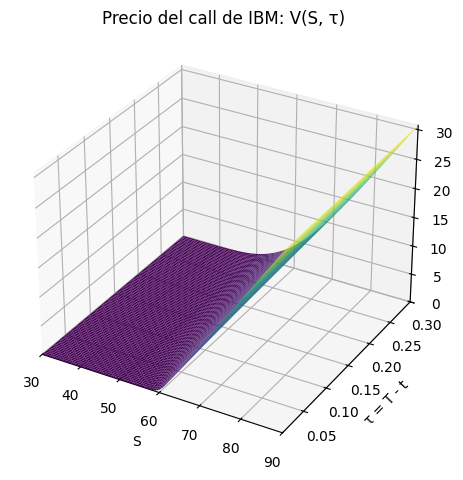

In [ ]:
# Superficie 1: precio de la opción V(S, tau)
p3a = plot3d(V_tau, (S, 30, 90), (tau, 0.005, 0.3), show=False,
             xlabel='S', ylabel='τ = T - t', zlabel='V',
             title='Precio del call de IBM: V(S, τ)')
p3a.show()

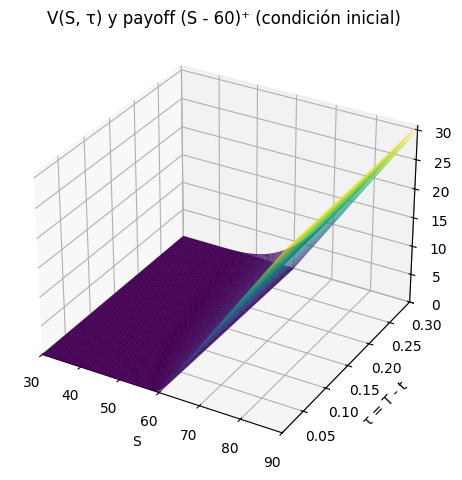

In [ ]:
# Superficie 2: V(S, tau) junto con el payoff (S - 60)^+ (la condición inicial, que no depende de tau)
# Se suma 1e-12*tau al payoff solo para que SymPy lo trate como función de (S, tau)
payoff_3d = Vbar_num + sp.Float('1e-12')*tau

p3b = plot3d(V_tau, payoff_3d, (S, 30, 90), (tau, 0.005, 0.3), show=False,
             xlabel='S', ylabel='τ = T - t', zlabel='V',
             title='V(S, τ) y payoff (S - 60)⁺ (condición inicial)')
p3b.show()

In [ ]:
# Definimos  u_xt (u(x, tau) = e^{alpha*x + beta*tau} * V(e^x, tau))
u_xt = sp.exp(alpha_num*x + beta_num*tau) * V_tau.subs(S, sp.exp(x))

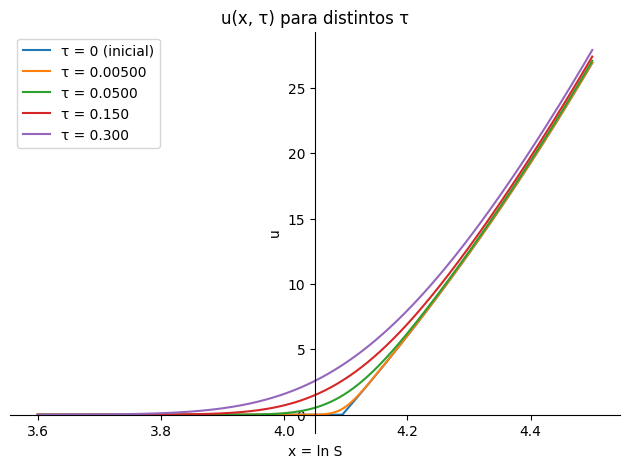

In [ ]:
# Cortes 2D: cómo evoluciona u(x, tau) a partir de la condición inicial u(x, 0)
taus = [sp.Rational(1, 200), sp.Rational(1, 20), sp.Rational(3, 20), sp.Rational(3, 10)]
curvas = [u0_x] + [u_xt.subs(tau, tv) for tv in taus]

pcortes = plot(*curvas, (x, 3.6, 4.5), show=False, legend=True,
               title='u(x, τ) para distintos τ', xlabel='x = ln S', ylabel='u')
etiquetas = ['τ = 0 (inicial)'] + ['τ = ' + str(sp.N(tv, 3)) for tv in taus]
for i, etq in enumerate(etiquetas):
    pcortes[i].label = etq
pcortes.show()

## <span style="color:teal;">**Conclusiones**</span>

1. La EDP de Black-Scholes se reduce a la **ecuación del calor** con tres cambios de variable: $\tau=T-t$, $S=e^x$ y $u=e^{\alpha x+\beta\tau}Z$, con $\alpha=\frac{r-q-\sigma^2/2}{\sigma^2}$ y $\beta=r+\frac{(r-q-\sigma^2/2)^2}{2\sigma^2}$.
2. La **fórmula de Green** da la solución explícita (3), y al usar el payoff $(S-E)^+$ la integral se resuelve completando el cuadrado, lo que lleva a la función de distribución normal $N$ (vía la función error).
3. Con SymPy se graficó la condición inicial $(S-60)^+$ en las tres variables ($S$, $Z$, $u$) y la evolución en 3D de $V(S,\tau)$ y de $u(x,\tau)$.
4. Para el call de IBM ($S=58.5$, $E=60$, $\sigma=0.29$, $r=0.04$, $T=0.3$): $V(58.5,0)\approx 3.3489$.